# Шаг 2. Девять базовых операций OpenCV на одной картинке

Почти любая система компьютерного зрения начинается с **предобработки** изображения:
перевести в серый, убрать шум, поднять яркость или контраст, найти границы.
В этом ноутбуке мы применим девять самых частых операций к одной фотографии трубы
и соберём результаты в один коллаж 3 × 3, чтобы сравнить их глазами.

**Структура ноутбука (алгоритм):**
1. Импортируем OpenCV и помощники.
2. Загружаем фото и уменьшаем его до 640 × 360, чтобы коллаж из 9 картинок влез в экран.
3. Применяем 8 операций: серый, негатив, размытие, яркость, контраст, поворот, порог, границы Canny.
4. Подписываем каждую картинку и склеиваем всё в коллаж 3 × 3.
5. Сохраняем коллаж в `collage.jpg` и показываем его.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session02")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## 1. Импорт библиотек и общих помощников

- `cv2` — библиотека **OpenCV**: чтение, обработка и показ изображений.
- `numpy` (`np`) — работа с массивами чисел. Картинка в OpenCV — это и есть массив NumPy.
- `common` — наш модуль из этой же папки (`common.py`) с маленькими помощниками:

| Имя | Что делает |
|-----|------------|
| `PIPE` | путь к фотографии трубы из датасета (`dataset/images/train/...`) |
| `load(path)` | прочитать картинку (работает и с русскими буквами в пути) |
| `save(path, img)` | сохранить картинку в файл |
| `show_nb(img)` | показать картинку прямо в ноутбуке, под ячейкой |
| `label(img, text)` | подписать картинку чёрной полосой сверху (только латиница) |
| `grid(images, cols)` | склеить несколько картинок одинакового размера в таблицу |
| `fit(img, w, h)` | уменьшить картинку, если она не влезает в заданный размер |

> Ноутбук нужно запускать из папки `session02`, иначе `import common` не найдёт модуль.

In [1]:
import cv2

from common import PIPE, grid, label, load, save, show_nb

## 2. Загружаем и уменьшаем картинку

`cv2.resize(img, (ширина, высота))` меняет размер. Обратите внимание: здесь порядок **(ширина, высота)**,
а в `img.shape` — `(высота, ширина)`. Все картинки коллажа должны быть одного размера, иначе их не склеить.

In [2]:
img = cv2.resize(load(PIPE), (640, 360))  # уменьшаем, чтобы коллаж влез в экран
print("Новый размер:", img.shape)

Новый размер: (360, 640, 3)


## 3. Восемь операций

| Операция | Функция | Как работает |
|----------|---------|--------------|
| Оттенки серого | `cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)` | три канала сводятся в один: `0.114·B + 0.587·G + 0.299·R` |
| Негатив | `255 - img` | каждое число `v` заменяется на `255 - v`: светлое становится тёмным |
| Сглаживание | `cv2.GaussianBlur(img, (15, 15), 0)` | каждый пиксель — взвешенное среднее соседей в окне 15 × 15 |
| Яркость | `cv2.convertScaleAbs(img, alpha=1.0, beta=60)` | `v · alpha + beta` = `v + 60`, результат обрезается до 0…255 |
| Контраст | `cv2.convertScaleAbs(img, alpha=1.8, beta=-80)` | `v · 1.8 − 80`: тёмное темнеет, светлое светлеет |
| Поворот | `cv2.rotate(img, cv2.ROTATE_180)` | переворот на 180° (есть ещё 90° по и против часовой) |
| Порог | `cv2.threshold(gray, 120, 255, THRESH_BINARY)` | пиксели ярче 120 → 255 (белые), остальные → 0 (чёрные) |
| Границы Canny | `cv2.Canny(gray, 80, 160)` | ищет места резкой смены яркости; 80 и 160 — нижний и верхний пороги |

> Почему не просто `img + 60`? Числа типа `uint8` при переполнении «заворачиваются»: `250 + 60 = 54`.
> `convertScaleAbs` же обрезает результат до 255 (**насыщение**).

`cv2.threshold` возвращает два значения: использованный порог и саму картинку. Первое нам не нужно, поэтому `_`.

In [3]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)                  # оттенки серого
negative = 255 - img                                          # негатив, то же что cv2.bitwise_not(img)
smooth = cv2.GaussianBlur(img, (15, 15), 0)                   # сглаживание (размытие)
bright = cv2.convertScaleAbs(img, alpha=1.0, beta=60)         # ярче: +60 к каждому числу
contrast = cv2.convertScaleAbs(img, alpha=1.8, beta=-80)      # контрастнее: умножить на 1.8
rotated = cv2.rotate(img, cv2.ROTATE_180)                     # поворот на 180°
_, binary = cv2.threshold(gray, 120, 255, cv2.THRESH_BINARY)  # порог: только чёрное и белое
edges = cv2.Canny(gray, 80, 160)                              # границы (контуры)

## 4. Собираем коллаж

`label()` подписывает каждую картинку, а `grid()` склеивает девять картинок в таблицу по 3 в ряд.
Серые картинки (один канал) `grid` сам превращает в трёхканальные, чтобы их можно было склеить с цветными.

In [4]:
collage = grid([
    label(img, "original"), label(gray, "grayscale"), label(negative, "negative"),
    label(smooth, "smooth"), label(bright, "brightness +60"), label(contrast, "contrast x1.8"),
    label(rotated, "rotate 180"), label(binary, "threshold 120"), label(edges, "Canny edges"),
])

## 5. Сохраняем и смотрим

Сохранено: collage.jpg


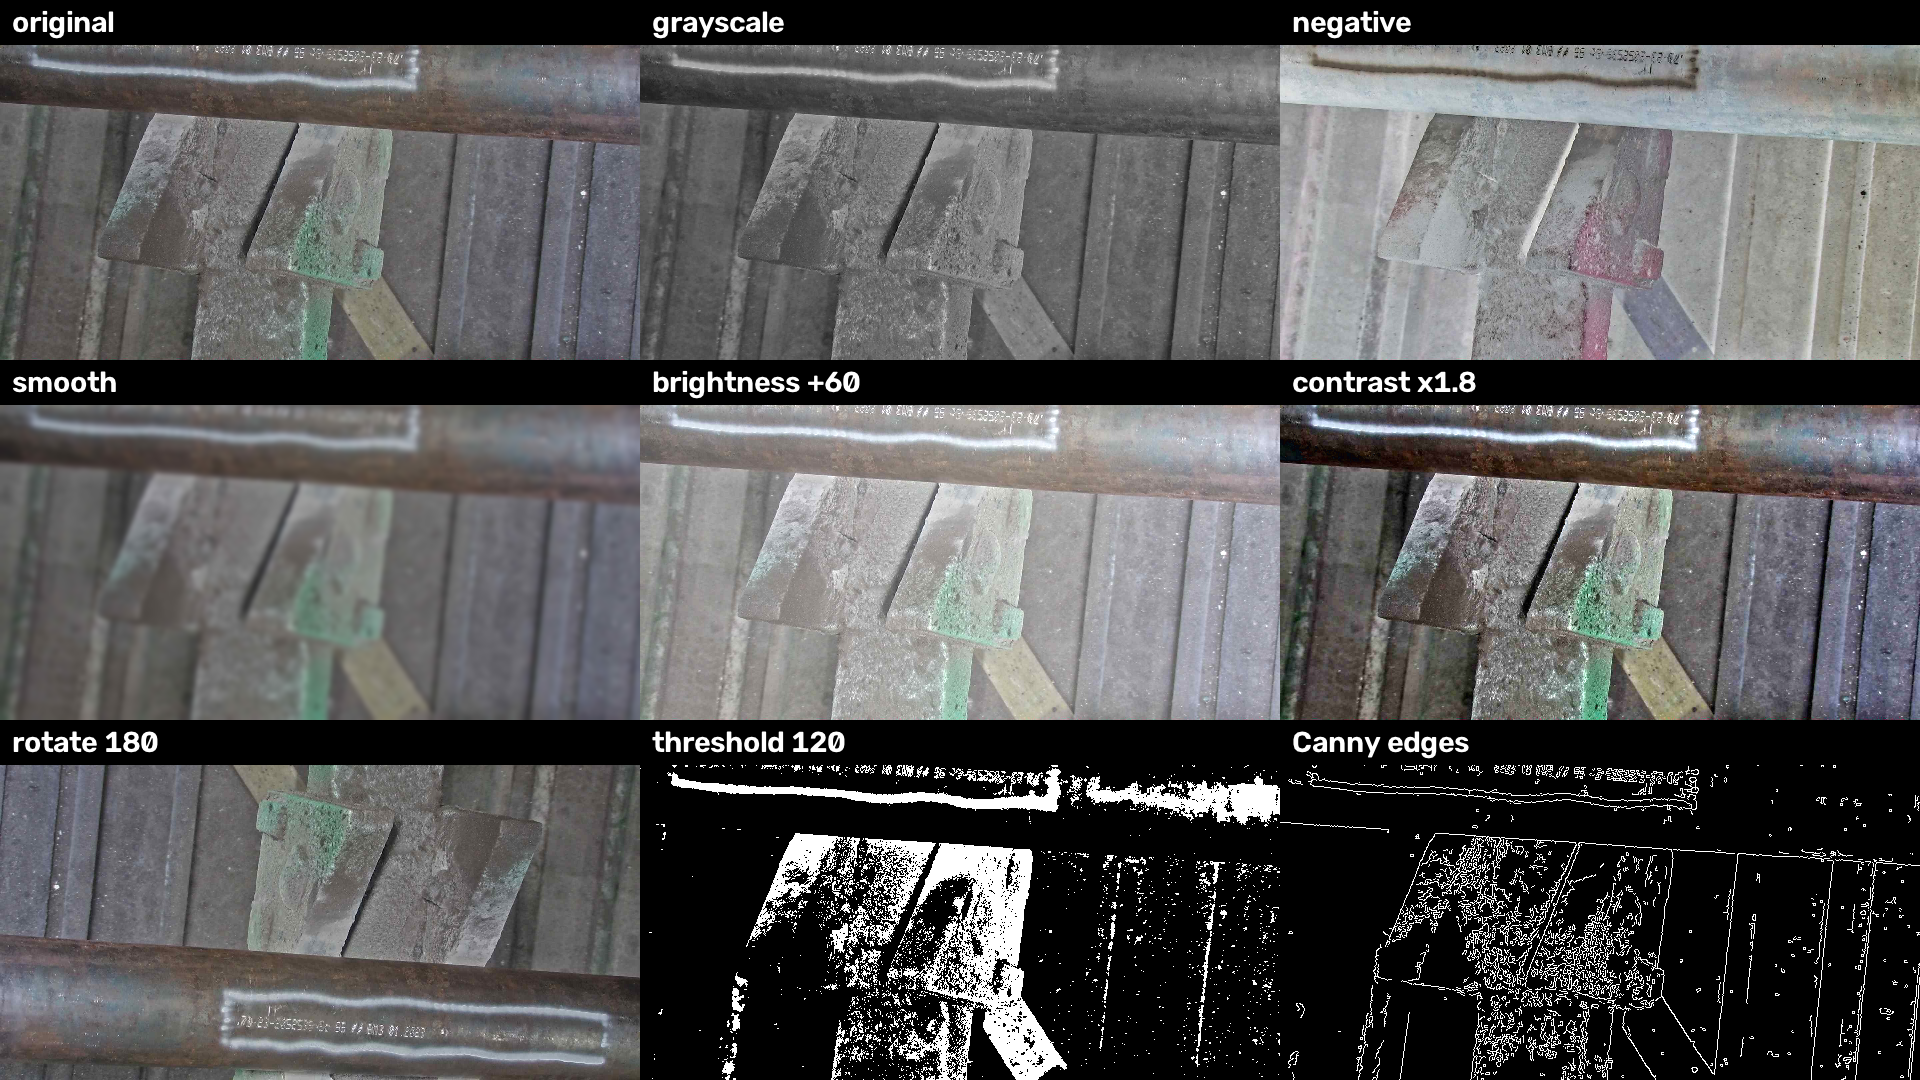

In [5]:
save("collage.jpg", collage)
show_nb(collage, 1920, 1080)

## Попробуйте сами

1. Поменяйте порог `120` на `60` и `200`. Где лучше видна маркировка?
2. Сравните `255 - img` и `cv2.bitwise_not(img)` — совпадают ли результаты? (подсказка: `(a == b).all()`)
3. Попробуйте `img + 60` вместо `convertScaleAbs`. Почему появились странные цветные пятна?
4. Поменяйте пороги Canny на `(30, 60)` и `(150, 300)`. Как меняется количество найденных границ?